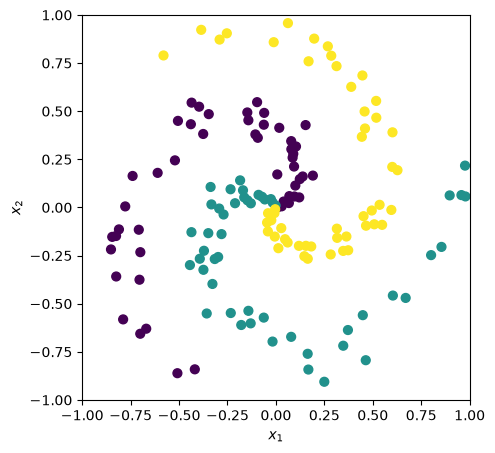

In [2]:
#################################################
#Edit to try different scenarios
#################################################
N = 50 # number of points per branch
K = 3  # number of branches
mag_noise = 0.3  # controls how much noise gets added to the data
dTheta    = 4    # difference in theta in each branch
#################################################

import matplotlib.pyplot as plt
import numpy as np


N_train = N*K # total number of points in the training set
x_train = np.zeros((N_train,2)) # initialize matrix containing the 2-dimensional datapoints
y_train = np.zeros(N_train, dtype='uint8') # initialize labels, positive integer


### Data generation: ###
for j in range(K):
  ix = range(N*j,N*(j+1))
  r  = np.linspace(0.01,1,N) # radius
  th = np.linspace(j*(2*np.pi)/K,j*(2*np.pi)/K + dTheta,N) + np.random.randn(N)*mag_noise # distribute points about theta curve
  x_train[ix] = np.c_[r*np.cos(th), r*np.sin(th)]
  y_train[ix] = j

### Plot the data set: ###
fig = plt.figure(1, figsize=(5,5))
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40)#, cmap=plt.cm.Spectral)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()


In [3]:
%matplotlib inline

In [23]:
%run ./functions.ipynb

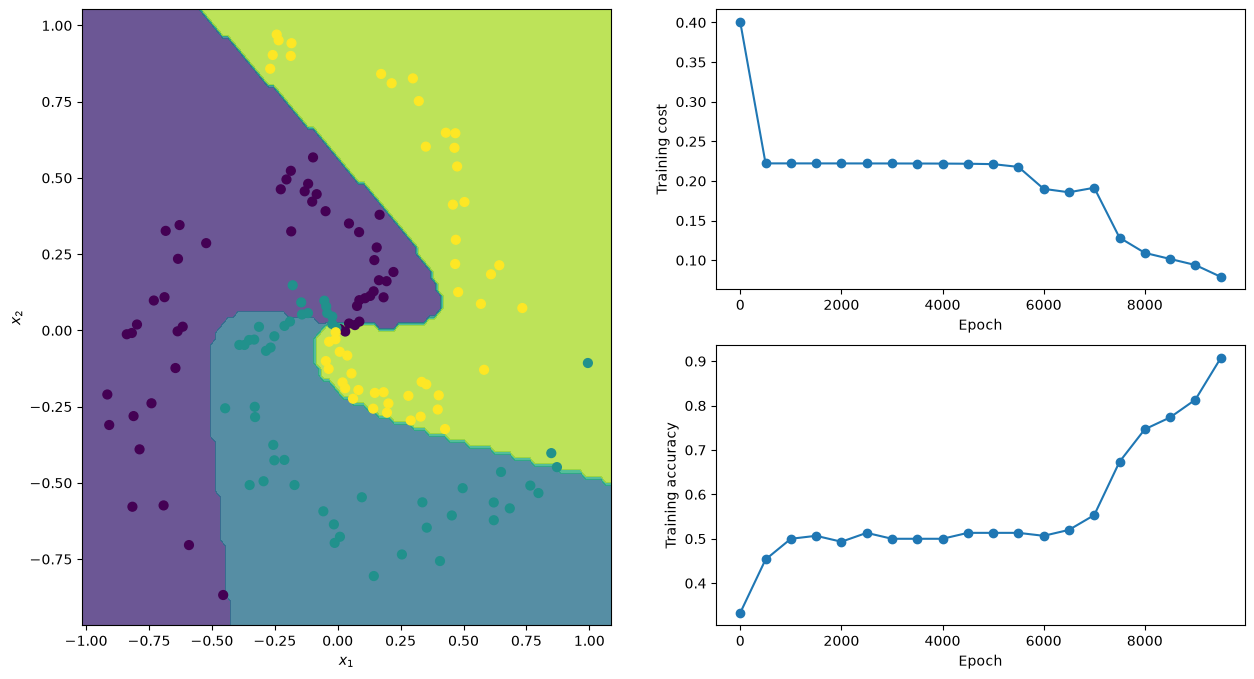

[SOFTMAX] Iteration 9500:
  Training cost 0.079119
  Training accuracy 0.906667

Saved spiral_results_softmax.pdf
Final SOFTMAX Training cost 0.059915
Final SOFTMAX Training accuracy 0.906667

--------------------------------------------------


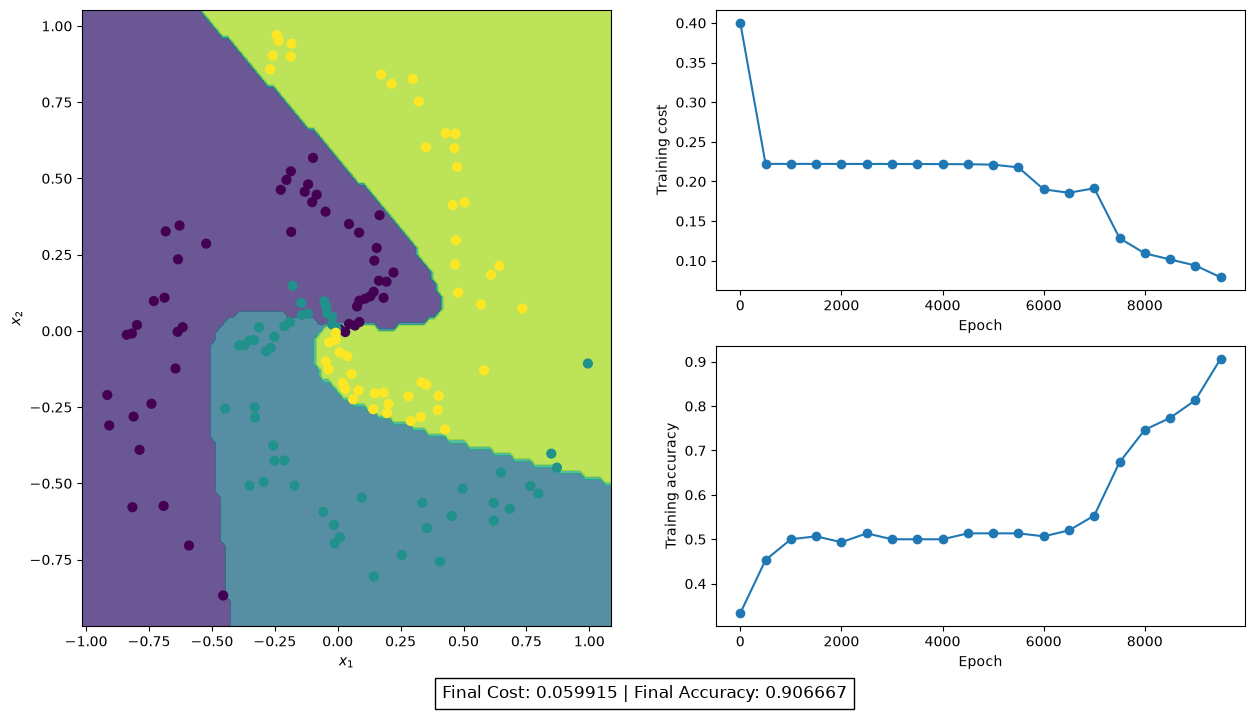

In [14]:
N_epochs = 10000

# Loop through different activation functions
for act in ('gauss', 'relu', 'sigmoid', 'softmax'):
    mid_size_array = [10, 8, 6]

    #get model variables
    model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(
        x_train, y_train, K, mid_size_array, 1.0, N_epochs, act
    )

    epoch_list    = []
    cost_training = []
    acc_training  = []

    ### Train for several epochs: ###
    for epoch in range(N_epochs):

        optimizer.zero_grad()
        NN_output = model(x_train_tensor) # Use the tensor returned by your setup function
        cost = cost_func(NN_output, y_onehot)
        cost.backward()
        optimizer.step()

        ### Update the plot and print results every 500 epochs: ###
        if epoch % 500 == 0:
            predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
            accuracy = np.mean(predicted_class == y_train)

            epoch_list.append(epoch)
            cost_training.append(cost.detach().numpy())
            acc_training.append(accuracy)

            ### Update the plot of the resulting classifier: ###
            fig = plt.figure(2, figsize=(15,8))
            fig.subplots_adjust(hspace=.3, wspace=.3)
            plt.clf()

            updatePlot(model,epoch_list,cost_training,acc_training)

            display.display(plt.gcf())
            print(f"[{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

            #Stop clearing the output on the very last step so the final plot stays visible
            if epoch < N_epochs - 500:
                display.clear_output(wait=True)
            # time.sleep(0.1)

    #
    metrics_text = f"Final Cost: {cost:.6f} | Final Accuracy: {accuracy:.6f}"
    plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12,
                bbox={"facecolor":"white", "pad":5})

    #Dynamically name the file based on the activation function
    filename = f'spiral_results_{act}.pdf'
    plt.savefig(filename, bbox_inches="tight")

    print(f"Saved {filename}")
    print(f"Final {act.upper()} Training cost {cost:.6f}\nFinal {act.upper()} Training accuracy {accuracy:.6f}\n")
    print("-" * 50)

In [ ]:
####################################################
#Next make a neural net to find ideal hyper-parameters for us
#{activation function, learning rate, number of hidden layers (capped), size of hidden layers (capped)
#####################################################

In [ ]:
#should be careful with mapping, especially with categorical variable like activation function

In [24]:
%run ./nnFornnHP.ipynb

In [25]:
#Execute the Neural Architecture Search
print("--- BEGINNING NEURAL ARCHITECTURE SEARCH ---")
#use 1/10th the epochs for training purposes
optimal_params = optimize_hyperparameters_with_nn(x_train, y_train, K, 50,1000)

#Extract the optimal parameters
best_act = optimal_params['activation']
best_lr = optimal_params['learning_rate']
best_layers = optimal_params['num_layers']
best_size = optimal_params['layer_size']

mid_size_array = [best_size] * best_layers
N_epochs = 10000

print("\n--- TRAINING FINAL MODEL WITH OPTIMAL HYPERPARAMETERS ---")
print(f"Configuration: Act={best_act.upper()}, LR={best_lr}, Layers={best_layers}, Size={best_size}")



--- BEGINNING NEURAL ARCHITECTURE SEARCH ---
Starting Neural Architecture Search...
Episode 01 | Reward: 0.6869 | Params: {'activation': 'softmax', 'learning_rate': 1.0, 'num_layers': 1, 'layer_size': 16}
Episode 02 | Reward: 0.2002 | Params: {'activation': 'sigmoid', 'learning_rate': 1.0, 'num_layers': 3, 'layer_size': 32}
Episode 03 | Reward: 0.6829 | Params: {'activation': 'softmax', 'learning_rate': 2.0, 'num_layers': 3, 'layer_size': 8}
Episode 04 | Reward: 0.7738 | Params: {'activation': 'gauss', 'learning_rate': 0.01, 'num_layers': 1, 'layer_size': 12}
Episode 05 | Reward: 1.4101 | Params: {'activation': 'relu', 'learning_rate': 0.5, 'num_layers': 2, 'layer_size': 32}
Episode 06 | Reward: 1.3553 | Params: {'activation': 'relu', 'learning_rate': 0.5, 'num_layers': 1, 'layer_size': 32}
Episode 07 | Reward: 1.2664 | Params: {'activation': 'relu', 'learning_rate': 0.5, 'num_layers': 1, 'layer_size': 16}
Episode 08 | Reward: 1.0612 | Params: {'activation': 'gauss', 'learning_rate': 2

In [22]:
# Setup the final model using original function
model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(
    x_train, y_train, K, mid_size_array, best_lr, N_epochs, best_act
)

epoch_list    = []
cost_training = []
acc_training  = []

# Execute the full training loop with live plotting
for epoch in range(N_epochs):
    optimizer.zero_grad()
    NN_output = model(x_train_tensor)
    cost = cost_func(NN_output, y_onehot)
    cost.backward()
    optimizer.step()

    # Update the plot and print results every 500 epochs
    if epoch % 500 == 0:
        predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
        accuracy = np.mean(predicted_class == y_train)

        epoch_list.append(epoch)
        cost_training.append(cost.detach().numpy())
        acc_training.append(accuracy)

        fig = plt.figure(2, figsize=(15,8))
        fig.subplots_adjust(hspace=.3, wspace=.3)
        plt.clf()

        updatePlot(model, epoch_list, cost_training, acc_training)

        display.display(plt.gcf())
        print(f"[{best_act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

        if epoch < N_epochs - 500:
            display.clear_output(wait=True)



# Save the final demonstration plot
metrics_text = f"Final Cost: {cost:.6f} | Final Accuracy: {accuracy:.6f}"
plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12, bbox={"facecolor":"white", "pad":5})

filename = f'spiral_results_OPTIMIZED_{best_act}.pdf'
plt.savefig(filename, bbox_inches="tight")

print(f"Saved {filename}")
print(f"Final {best_act.upper()} Training cost {cost:.6f}\nFinal {best_act.upper()} Training accuracy {accuracy:.6f}\n")

Saved spiral_results_OPTIMIZED_relu.pdf
Final RELU Training cost 0.013780
Final RELU Training accuracy 1.000000



<Figure size 640x480 with 0 Axes>